In [1]:
import pandas as pd, numpy as np, joblib

target = "SeriousDlqin2yrs"
va = pd.read_csv("../data/clean/val_clean.csv")
X_va, y_va = va.drop(columns=target), va[target].values

xgb = joblib.load("../models/xgb.joblib")
iso_xgb = joblib.load("../models/iso_xgb.joblib")
pd_va = iso_xgb.predict(xgb.predict_proba(X_va)[:, 1])

bins = [-np.inf, 0.02, 0.05, 0.10, 0.20, np.inf]
labels = ["A", "B", "C", "D", "E"]
grade = pd.cut(pd_va, bins=bins, labels=labels, right=False)

tbl = (pd.DataFrame({"grade": grade, "pd": pd_va, "y": y_va})
       .groupby("grade", observed=False)
       .agg(borrowers=("y", "size"), mean_pd=("pd", "mean"), actual_default=("y", "mean")))
tbl["share"] = tbl["borrowers"] / tbl["borrowers"].sum()
print(tbl.round(4))

       borrowers  mean_pd  actual_default   share
grade                                            
A          12051   0.0094          0.0094  0.5356
B           3125   0.0314          0.0314  0.1389
C           3844   0.0723          0.0723  0.1708
D           1172   0.1280          0.1280  0.0521
E           2308   0.3748          0.3748  0.1026


In [2]:
import os

te = pd.read_csv("../data/clean/test_clean.csv")
X_te, y_te = te.drop(columns=target), te[target].values

pd_te = iso_xgb.predict(xgb.predict_proba(X_te)[:, 1])
grade_te = pd.cut(pd_te, bins=bins, labels=labels, right=False)

tbl_te = (pd.DataFrame({"grade": grade_te, "pd": pd_te, "y": y_te})
          .groupby("grade", observed=False)
          .agg(borrowers=("y", "size"), mean_pd=("pd", "mean"), actual_default=("y", "mean")))
tbl_te["share"] = tbl_te["borrowers"] / tbl_te["borrowers"].sum()
print(tbl_te.round(4))

os.makedirs("../reports", exist_ok=True)
tbl.to_csv("../reports/grade_table_val.csv")
tbl_te.to_csv("../reports/grade_table_test.csv")
joblib.dump({"bins": bins, "labels": labels}, "../models/grade_config.joblib")

       borrowers  mean_pd  actual_default   share
grade                                            
A          11938   0.0094          0.0111  0.5306
B           3123   0.0311          0.0327  0.1388
C           3958   0.0710          0.0682  0.1759
D           1230   0.1287          0.1390  0.0547
E           2251   0.3709          0.3678  0.1000


['../models/grade_config.joblib']

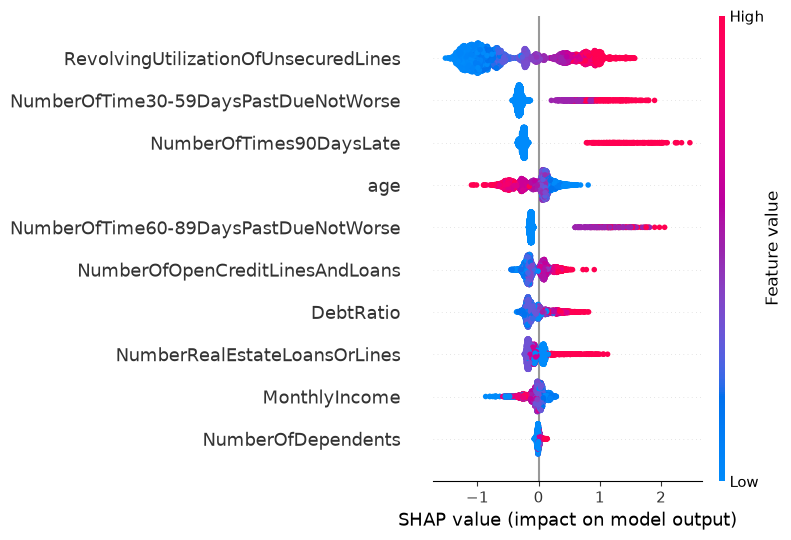

RevolvingUtilizationOfUnsecuredLines    0.826
NumberOfTime30-59DaysPastDueNotWorse    0.391
NumberOfTimes90DaysLate                 0.315
age                                     0.236
NumberOfTime60-89DaysPastDueNotWorse    0.178
NumberOfOpenCreditLinesAndLoans         0.162
DebtRatio                               0.154
NumberRealEstateLoansOrLines            0.122
MonthlyIncome                           0.101
NumberOfDependents                      0.018
dtype: float32

Peminjam #5: PD=0.182, grade=D, default aktual=0
                                       nilai   shap
NumberOfTime30-59DaysPastDueNotWorse   1.000  0.482
RevolvingUtilizationOfUnsecuredLines   0.683  0.438
NumberOfTimes90DaysLate                0.000 -0.273
age                                   30.000  0.239
NumberOfTime60-89DaysPastDueNotWorse   0.000 -0.143


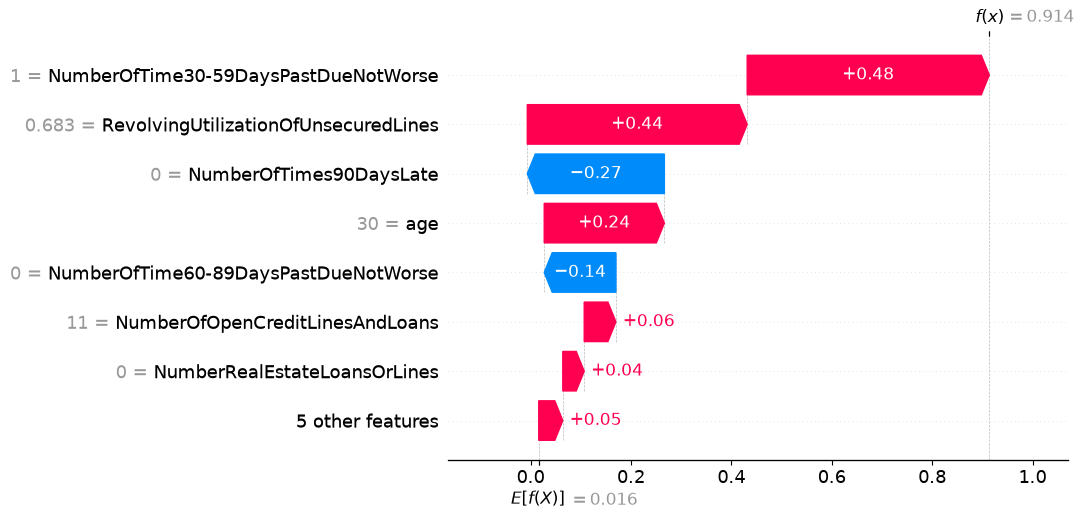

In [3]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(xgb)

# 1. Penjelasan global (sampel 5.000 baris test)
sample = X_te.sample(5000, random_state=42)
sv = explainer.shap_values(sample)

plt.figure()
shap.summary_plot(sv, sample, max_display=10, show=False)
plt.tight_layout()
plt.savefig("../reports/shap_global.png", dpi=150, bbox_inches="tight")
plt.show()

imp = pd.Series(np.abs(sv).mean(axis=0), index=sample.columns).sort_values(ascending=False)
print(imp.head(10).round(3))

# 2. Penjelasan satu peminjam grade D
idx = int(np.where(np.asarray(grade_te) == "D")[0][0])
row = X_te.iloc[[idx]]
sv1 = explainer.shap_values(row)[0]

print()
print(f"Peminjam #{idx}: PD={pd_te[idx]:.3f}, grade={grade_te[idx]}, default aktual={y_te[idx]}")
detail = pd.DataFrame({"nilai": row.iloc[0], "shap": sv1}).reindex(
    pd.Series(sv1, index=row.columns).abs().sort_values(ascending=False).index
)
print(detail.head(5).round(3))

exp = shap.Explanation(values=sv1,
                       base_values=float(np.ravel(explainer.expected_value)[0]),
                       data=row.iloc[0].values,
                       feature_names=list(row.columns))
plt.figure()
shap.plots.waterfall(exp, max_display=8, show=False)
plt.savefig("../reports/shap_borrower_D.png", dpi=150, bbox_inches="tight")
plt.show()

In [4]:
sv_te = explainer.shap_values(X_te)
cols = list(X_te.columns)
Xv = X_te.values

label = {
    "RevolvingUtilizationOfUnsecuredLines": "Utilisasi kredit",
    "age": "Usia",
    "NumberOfTime30-59DaysPastDueNotWorse": "Telat 30-59 hari",
    "DebtRatio": "Debt ratio",
    "MonthlyIncome": "Income bulanan",
    "NumberOfOpenCreditLinesAndLoans": "Jumlah kredit aktif",
    "NumberOfTimes90DaysLate": "Telat 90+ hari",
    "NumberRealEstateLoansOrLines": "Kredit properti",
    "NumberOfTime60-89DaysPastDueNotWorse": "Telat 60-89 hari",
    "NumberOfDependents": "Jumlah tanggungan",
    "income_missing": "Income tidak tercatat",
    "late_code_flag": "Kode keterlambatan khusus",
}

def top3_reasons(i):
    order = np.argsort(-sv_te[i])[:3]
    parts = [f"{label[cols[j]]} = {Xv[i, j]:g}" for j in order if sv_te[i][j] > 0]
    return " | ".join(parts)

scored = X_te.copy()
scored["PD"] = pd_te
scored["grade"] = np.asarray(grade_te)
scored["actual_default"] = y_te
scored["reasons"] = [top3_reasons(i) for i in range(len(X_te))]
scored.to_csv("../reports/scored_test.csv", index=False)

print(scored.shape)
print(scored.sort_values("PD", ascending=False)
      .head(5)[["PD", "grade", "actual_default", "reasons"]]
      .to_string())

(22500, 16)
        PD grade  actual_default                                                                 reasons
10059  1.0     E               1  Telat 90+ hari = 3 | Utilisasi kredit = 1.06723 | Telat 60-89 hari = 5
11829  1.0     E               1  Telat 90+ hari = 5 | Utilisasi kredit = 1.09531 | Telat 60-89 hari = 2
11584  1.0     E               1  Telat 90+ hari = 5 | Telat 60-89 hari = 2 | Utilisasi kredit = 1.00946
15531  1.0     E               1        Telat 90+ hari = 7 | Telat 60-89 hari = 2 | Telat 30-59 hari = 2
3540   1.0     E               1  Telat 90+ hari = 6 | Telat 60-89 hari = 3 | Utilisasi kredit = 1.09531
